## GWFish: Lunar Gravitational-Wave Antenna (LGWA) Extension

This tutorial shows how to simulate and evaluate parameter estimation for the **Lunar Gravitational-Wave Antenna (LGWA)** in `GWFish`, both as a standalone detector and in multi-band networks (e.g., with Einstein Telescope).

### Overview of LGWA Support

- **LGWA Detector Configuration:** Adds the `LGWA` detector profile, enabling the projection of gravitational-wave signals onto a simulated lunar array.
- **Mid-Band Sensitivity:** Integrates LGWA's Power Spectral Density (PSD), bridging the frequency gap between space-based (LISA) and ground-based (ET/CE) detectors.
- **Lunar Network Synergies:** Combines LGWA with detectors to evaluate multi-band network SNRs and parameter constraints.

### Important Caution: LGWA Reference Frame

**Please read before interpreting simulation results.**

At its current stage, **this implementation does not yet include the exact prescription of the reference frame for the Earth-Moon system.**

Because gravitational waves can remain in the LGWA sensitivity band for weeks, months, or even years (e.g., for solar-mass compact binaries or massive BH binaries), the changing orientation and position of the Moon are critical for exact signal processing.
Consequently, users should be aware of the following limitations:

1. **Coordinate Projections:** The pipeline currently relies on simplified coordinate approximations to project the waveform onto the LGWA detector. It does not fully account for precise lunar-centric coordinate transformations, the Moon's exact orbital ephemerides, or its rotational librations.
2. **Sky Localization Constraints:** Because the exact phase delays relative to the Earth/Solar System barycenter are not rigorously modeled over long durations, metrics that depend heavily on time-delay interferometry and exact baseline phase correlations (most notably **sky localization**) will be approximations.
3. **Time-Dependent Response:** The time-varying detector response (antenna pattern) lacks the exact Earth-Moon-Sun orbital mechanics required for highly precise long-duration parameter estimation.

*While this module provides an excellent tool for order-of-magnitude SNR estimates and general parameter constraints, high-precision results (especially sub-degree sky localizations) should be treated as preliminary until the exact lunar reference frame is fully implemented.*

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18 as cosmo

from lgwa_response.lunar_coordinates import arbitrary_grid
from lgwa_response.bilby_interface import LunarLikelihoodBilbyInjection
from lgwa_response.likelihood import LunarLikelihood

import GWFish.modules as gwfish
import GWFish.modules.fishermatrix_lgwa as lgwa

/home/matteo/anaconda3/envs/forkedGWFish_lgwa/lib/python3.11/site-packages/bilby/core/likelihood.py:83: FutureWarning: <class 'lgwa_response.bilby_interface.LunarLikelihoodBilbyInjection'> log_likelihood or log_likelihood_ratio method does not accept 'parameters' as an argument. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(


#### Define Source Parameters (GW170817-like BNS)

In [5]:
np.random.seed(42)

t0 = 1200000000.0
z = 0.00980

parameters = {
    'chirp_mass': np.array([1.1858999987203738]) * (1 + 0.00980), 
    'mass_ratio': np.array([0.8308538032620448]), 
    'luminosity_distance': cosmo.luminosity_distance(0.00980).value,
    'theta_jn': np.array([2.545065595974997]),
    'ra': np.array([3.4461599999999994]),
    'dec': np.array([-0.4080839999999999]),
    'psi': np.array([0.]),
    'phase': np.array([0.]),
    'geocent_time': np.array([1187008882.4]),
    'a_1':np.array([0.005136138323169717]), 
    'a_2':np.array([0.003235146993487445]), 
    'lambda_1':np.array([368.17802383555687]), 
    'lambda_2':np.array([586.5487031450857])}

parameters = pd.DataFrame(parameters)

parameters

,chirp_mass,mass_ratio,luminosity_distance,theta_jn,ra,dec,psi,phase,geocent_time,a_1,a_2,lambda_1,lambda_2
0,1.197522,0.830854,43.747554,2.545066,3.44616,-0.408084,0.0,0.0,1.187009e+09,0.005136,0.003235,368.178024,586.548703


#### Single-Detector LGWA Fisher Matrix & Projected Signal

In [6]:
freqs = arbitrary_grid(0.02710126, 3.0, n_samples=5000)
fisher_parameters = ['chirp_mass', 'mass_ratio', 'phase', 'ra', 'dec', 'psi', 'luminosity_distance', 'theta_jn']

likelihood_inj = LunarLikelihoodBilbyInjection()
lgwa_params = lgwa.from_gwfish2lgwa_paramnames(parameters.iloc[0])

likelihood_inj.compute_center(lgwa_params['time_at_center'])

detector_fisher, detector_snr_square = lgwa.compute_detector_fisher(freqs, likelihood_inj, lgwa_params, fisher_parameters)
signal = likelihood_inj.projected_waveform(freqs, lgwa_params)

print(f"LGWA Optimal SNR: {np.sqrt(detector_snr_square):.4f}")

/home/matteo/anaconda3/envs/forkedGWFish_lgwa/lib/python3.11/site-packages/bilby/core/likelihood.py:127: FutureWarning: Setting non-trivial parameters for <class 'lgwa_response.bilby_interface.LunarLikelihoodBilbyInjection'>. This is deprecated behaviour  and will be removed in Bilby version 3. See https://bilby-dev.github.io/bilby/parameters for more details.
  warnings.warn(msg, FutureWarning)


LGWA Optimal SNR: 23.0075


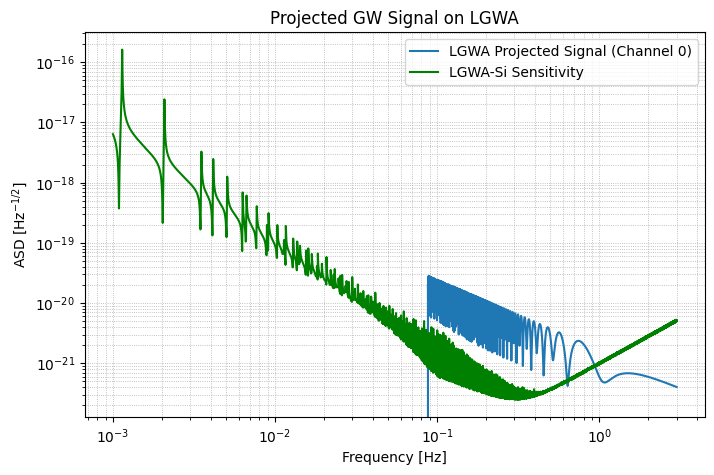

In [ ]:
plt.figure(figsize=(8, 5))
plt.loglog(freqs, np.abs(signal[0, :]), label='LGWA Projected Signal (Channel 0)')

# Optional: overlay LGWA sensitivity curve from the PSD file 
#psd_data = np.loadtxt('/path/to/LGWA_psd.txt')
#plt.loglog(psd_data[:, 0], np.sqrt(psd_data[:, 0] * psd_data[:, 1]), color='green', label='LGWA Sensitivity')

plt.xlabel('Frequency [Hz]')
plt.ylabel(r'ASD [Hz$^{-1/2}$]')
plt.title('Projected GW Signal on LGWA')
plt.grid(linestyle='dotted', linewidth=0.6, which='both')
plt.legend()
plt.show()

#### GWFish Network Errors: LGWA Only

In [12]:
likelihood = LunarLikelihood()

detected_lgwa, snr_lgwa, errors_lgwa, sky_loc_lgwa = gwfish.fishermatrix.compute_network_errors(
    network=gwfish.detection.Network(detector_ids=['LGWA'], detection_SNR=(0., 8.)),
    parameter_values=parameters,
    fisher_parameters=fisher_parameters,
    f_lgwa=freqs,
    lunarLikelihood=likelihood,
)

print("Detected indices:", detected_lgwa)
print("Network SNR:", snr_lgwa)
print("Sky localization:", sky_loc_lgwa)
pd.DataFrame(errors_lgwa, columns=fisher_parameters)

100%|██████████| 1/1 [00:00<00:00,  2.35it/s]

Detected indices: [0]
Network SNR: [23.00750749]
Sky localization: [8.64371549e-08]


,chirp_mass,mass_ratio,phase,ra,dec,psi,luminosity_distance,theta_jn
0,3.883592e-08,0.003001,4.778105,0.000194,0.000278,2.392175,35.93946,1.343746


#### GWFish Network Errors: Multi-Detector (LGWA + ET)

In [13]:
f_grid = np.geomspace(1e-2, 3.0, num=1000)

fisher_params_multi = ['mass_ratio', 'chirp_mass', 'luminosity_distance']

# Drop tidal parameters when using IMRPhenomD
params_no_tidal = parameters.drop(columns=['lambda_1', 'lambda_2'])

detected_net, snr_net, errors_net, sky_loc_net = gwfish.fishermatrix.compute_network_errors(
    network=gwfish.detection.Network(detector_ids=['LGWA', 'ET'], detection_SNR=(0., 8.)),
    parameter_values=params_no_tidal,
    fisher_parameters=fisher_params_multi,
    f_lgwa=f_grid,
    lunarLikelihood=likelihood,
    waveform_model='IMRPhenomD',
)

print("Detected indices:", detected_net)
print("Network SNR (LGWA + ET):", snr_net)
print("Sky localization:", sky_loc_net)
pd.DataFrame(errors_net, columns=fisher_params_multi)

100%|██████████| 1/1 [00:00<00:00,  1.27it/s]

Detected indices: [0]
Network SNR (LGWA + ET): [645.6068795]
Sky localization: None


,mass_ratio,chirp_mass,luminosity_distance
0,0.000124,2.108609e-09,0.067762
